In [1]:
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import (
    LinearRegression, SGDRegressor, HuberRegressor, TheilSenRegressor, RANSACRegressor, QuantileRegressor
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR, LinearSVR, NuSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels.csv', index_col='ID')
categorical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_categorical_features.csv', index_col='ID')
numerical_features=pd.read_csv('/Users/fserracrespi/Desktop/TRABAJO FINAL ML VSCode/DataModels_numercial_features.csv', index_col='ID')

## 🛑 Task 2.2: WBLC

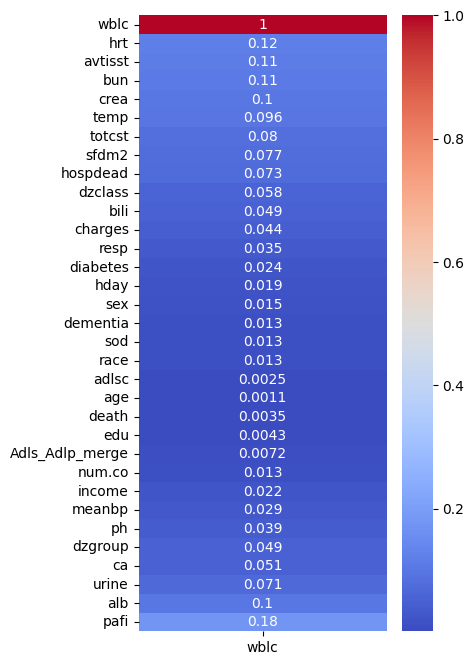

In [2]:
plt.figure(figsize=(4, 8))
sns.heatmap(df.corr()["wblc"].sort_values(ascending=False).abs().to_frame(), annot=True, cmap='coolwarm')
plt.show()

The variables are not highly linearly correlated

### 🛑  Model Analysis

In [3]:
target=df['wblc']
features=df.drop(['wblc'],axis=1)
categorical_features_cols= categorical_features.columns
numerical_features_cols = numerical_features.columns.drop('wblc').tolist()



In [4]:
# Definir StratifiedKFold (estratificando la variable objetivo discretizada)
bins = pd.qcut(target, q=5, labels=False)  # Discretizar en quintiles
kfold_external = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
data_dict = {}
# Crear un DataFrame para guardar resultados
evaluation_metrics_scaled = pd.DataFrame(columns=['Model', 'MAE_VAL', 'MAPE_VAL', 'RMSE_VAL', 'R2_VAL', 'R2_adjusted_VAL', 'MAE_TRAIN', 'MAPE_TRAIN', 'RMSE_TRAIN', 'R2_TRAIN', 'R2_adjusted_TRAIN'])

# Función para calcular métricas
def evaluate_model(y_true, y_pred, n, p):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    r2 = r2_score(y_true, y_pred)
    r2_adjusted = 1 - ((1 - r2) * (n - 1) / (n - p - 1))
    return mae, mape, rmse, r2, r2_adjusted

# Modelos de regresión
models = {
    "Linear Regression": LinearRegression(),
    "Quantile Regression": QuantileRegressor(quantile=0.5),
    "Polynomial Regression (Degree=2)": Pipeline([
        ("poly_features", PolynomialFeatures(degree=2)),
        ("linear_regression", LinearRegression())
    ]),
    "Linear SVR": LinearSVR(random_state=42),
    "SVR": SVR(),
    "NuSVR": NuSVR(),
    "SGD Regression": SGDRegressor(random_state=42),
    "Nearest Neighbor Regression": KNeighborsRegressor(),
    "Decision Tree Regression": DecisionTreeRegressor(random_state=42),
    "RANSAC Regression": RANSACRegressor(random_state=42),
    "Theil-Sen Regression": TheilSenRegressor(random_state=42),
    "Huber Regressor": HuberRegressor()
}

for fold, (train_val_index, test_index) in enumerate(kfold_external.split(features, bins)):
    fold_external_dict = {}
    # Dividir en conjunto de prueba y conjunto de entrenamiento/validación
    X_train_val, X_test = features.iloc[train_val_index], features.iloc[test_index]
    y_train_val, y_test = target.iloc[train_val_index], target.iloc[test_index]
    
    # Índices alineados 
    bins_train_val = bins.iloc[train_val_index]
    
    # Inicialización de KFold interno
    kfold_internal = StratifiedKFold(n_splits=2, shuffle=True, random_state=42)
    number=1
    for train_index, val_index in kfold_internal.split(X_train_val, bins_train_val):
        # División en conjuntos de entrenamiento y validación
        X_train = X_train_val.iloc[train_index]
        y_train = y_train_val.iloc[train_index]
        X_val = X_train_val.iloc[val_index]
        y_val = y_train_val.iloc[val_index]

        # Separar variables cuantitativas y cualitativas
        X_train_quantitative = X_train[numerical_features_cols]
        X_val_quantitative = X_val[numerical_features_cols]
        X_test_quantitative = X_test[numerical_features_cols]
        X_train_qualitative = pd.get_dummies(X_train[categorical_features_cols], drop_first=True)
        X_val_qualitative = pd.get_dummies(X_val[categorical_features_cols], drop_first=True)
        X_test_qualitative = pd.get_dummies(X_test[categorical_features_cols], drop_first=True)
        
        # Normalizar datos
        # Initialize the scaler
        scaler = StandardScaler()

        # Fit and transform on the training data, preserving the index
        X_scaled_train = scaler.fit_transform(X_train_quantitative)
        X_scaled_train = pd.DataFrame(X_scaled_train, columns=X_train_quantitative.columns, index=X_train_quantitative.index)

        # Transform validation data (using the same scaler fitted on training data), preserving the index
        X_scaled_val = scaler.transform(X_val_quantitative)
        X_scaled_val = pd.DataFrame(X_scaled_val, columns=X_val_quantitative.columns, index=X_val_quantitative.index)

        # Transform test data (using the same scaler fitted on training data), preserving the index
        X_scaled_test = scaler.transform(X_test_quantitative)
        X_scaled_test = pd.DataFrame(X_scaled_test, columns=X_test_quantitative.columns, index=X_test_quantitative.index)

        X_scaled_train=pd.concat([X_scaled_train,X_train_qualitative],axis=1)
        X_scaled_val=pd.concat([X_scaled_val,X_val_qualitative],axis=1)
        X_scaled_test=pd.concat([X_scaled_test,X_test_qualitative],axis=1)

        # Guardar los datos procesados
        fold_internal_key = f'Fold_Interno_{number}'
        fold_external_dict[fold_internal_key] = {
            'Train_X': X_scaled_train,
            'Train_Y': y_train,
            'Validation_X': X_scaled_val,
            'Validation_Y': y_val,
            'Test_X': X_scaled_test,
            'Test_Y': y_test
        }

        # Guardar el fold externo con todos los internos
        fold_external_key = f'Fold_Externo_{fold}'
        data_dict[fold_external_key] = fold_external_dict

        for model_name, model in models.items():
            # Ajustar el modelo y realizar predicciones
            model.fit(X_scaled_train, y_train)
            y_pred = model.predict(X_scaled_val)

            # Calcular las métricas para el set de validación
            n, p = X_scaled_test.shape
            mae, mape, rmse, r2, r2_adjusted = evaluate_model(y_val, y_pred, n, p)

           

            # Calculando las métricas para el conjunto de train
            mae_train, mape_train, rmse_train, r2_train, r2_adjusted_train = evaluate_model(y_train, model.predict(X_scaled_train), n, p)

            # Registrar las métricas
            model_row = pd.DataFrame([{
                'Model': model_name,
                'MAE_VAL': mae,
                'MAPE_VAL': mape,
                'RMSE_VAL': rmse,
                'R2_VAL': r2,
                'R2_adjusted_VAL': r2_adjusted,
                'MAE_TRAIN': mae_train,
                'MAPE_TRAIN': mape_train,
                'RMSE_TRAIN': rmse_train,
                'R2_TRAIN': r2_train,
                'R2_adjusted_TRAIN': r2_adjusted_train

            }])
            evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)
        number=number+1


/var/folders/vr/_v9wq92941bflv75jsh8kq800000gn/T/ipykernel_76930/3102893278.py:127: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  evaluation_metrics_scaled = pd.concat([evaluation_metrics_scaled, model_row], ignore_index=True)


In [5]:
evaluation_metrics_scaled.groupby('Model').mean().sort_values('R2_adjusted_VAL', ascending=False)

,MAE_VAL,MAPE_VAL,RMSE_VAL,R2_VAL,R2_adjusted_VAL,MAE_TRAIN,MAPE_TRAIN,RMSE_TRAIN,R2_TRAIN,R2_adjusted_TRAIN
Model,,,,,,,,,,
Linear Regression,5.466620,inf,8.857135,0.057684,0.040242,5.419288e+00,inf,8.785394e+00,0.072935,0.055775
NuSVR,5.260858,inf,8.863068,0.056516,0.039052,5.123183e+00,inf,8.721102e+00,0.086530,0.069622
Theil-Sen Regression,5.387356,inf,8.877510,0.053392,0.035870,5.347083e+00,inf,8.833582e+00,0.062759,0.045410
SGD Regression,5.519614,inf,8.907708,0.046998,0.029358,5.472534e+00,inf,8.834747e+00,0.062423,0.045068
SVR,5.244532,inf,8.916790,0.045007,0.027331,5.007989e+00,inf,8.761369e+00,0.078116,0.061052
Huber Regressor,5.304047,inf,8.931794,0.041795,0.024059,5.251656e+00,inf,8.892056e+00,0.050330,0.032752
Linear SVR,5.308124,inf,8.970107,0.033593,0.015705,5.243073e+00,inf,8.933714e+00,0.041382,0.023638
Quantile Regression,5.588117,inf,9.306984,-0.040440,-0.059698,5.587662e+00,inf,9.306881e+00,-0.040443,-0.059701
Nearest Neighbor Regression,5.850536,inf,9.479329,-0.080016,-0.100007,4.754998e+00,inf,7.670521e+00,0.292862,0.279773


--- 
# ⭐️ GENERAL CONCLUSIONS BETTER MODEL DUE TO THEIR PERFORMANCE

# Regression Models Analysis

## 1. Best Performing Models
The best models are **NuSVR** and **SVR**, with the lowest error values (MAE and RMSE) and relatively better \( R^2 \) values for validation:

- **NuSVR**:  
  - **MAE_VAL** = 5.26  
  - **RMSE_VAL** = 8.86  
  - **R2_VAL** = 0.056  

- **SVR**:  
  - **MAE_VAL** = 5.24  
  - **RMSE_VAL** = 8.91  
  - **R2_VAL** = 0.045  

These models achieve the best balance between validation error and training generalization despite low overall \( R^2 \).

---

## 2. Similar Performing Models  
Models such as **Huber Regressor**, **Linear Regression**, and **Theil-Sen Regression** show similar results with slightly higher errors but remain among the top-performing models:  

- **Huber Regressor**:  
  - **MAE_VAL** = 5.30  
  - **RMSE_VAL** = 8.93  
  - **R2_VAL** = 0.041  

- **Theil-Sen Regression**:  
  - **MAE_VAL** = 5.38  
  - **RMSE_VAL** = 8.87  
  - **R2_VAL** = 0.053  

- **Linear Regression**:  
  - **MAE_VAL** = 5.47  
  - **RMSE_VAL** = 8.85  
  - **R2_VAL** = 0.057  

These models are consistent but do not outperform **NuSVR** or **SVR**.

---

## 3. Worst Performing Models  
**Decision Tree Regression** and **RANSAC Regression** perform the worst, indicating overfitting or a complete failure to generalize:

- **Decision Tree Regression**:  
  - **R2_VAL** = -1.03  
  - **RMSE_VAL** = 12.97  

- **RANSAC Regression**:  
  - **R2_VAL** = -4.50  
  - **RMSE_VAL** = 20.00  
  - **MAE_VAL** = 12.35  

These models are unable to capture the underlying patterns in the data and fail during validation.

---

## 4. Polynomial and Nearest Neighbor Models  
- **Polynomial Regression (Degree=2)** and **Nearest Neighbor Regression** exhibit lower predictive capacity:  

- **Polynomial Regression (Degree=2)**:  
  - **R2_VAL** = -0.23  
  - **RMSE_VAL** = 10.07  

- **Nearest Neighbor Regression**:  
  - **R2_VAL** = -0.08  
  - **RMSE_VAL** = 9.48  

Both models show poor performance, with Polynomial Regression suffering from overfitting.

---

## 5. Model Generalization  
- Models such as **Decision Tree Regression** and **Polynomial Regression (Degree=2)** show significant overfitting:  
  - **R2_TRAIN** is much higher (1.0 for Decision Tree, 0.27 for Polynomial) compared to **R2_VAL** (-1.03 and -0.23 respectively).  

- Conversely, **NuSVR**, **Linear SVR**, and **Huber Regressor** maintain relatively balanced error values between validation and training sets, which indicates better generalization despite low \( R^2 \) scores overall.

---

## 6. Limitations and Next Steps
Given the **limited time** and overall poor performance of all models, we have not done any further tuning or exploration of these models at this stage. However, these results could be **significantly improved** with:
- More appropriate training (more data or better preprocessing).
- Better adjustment and optimization of parameters.
- Advanced techniques such as **hyperparameter optimization** (e.g. GridSearch, Bayesian optimization).

To satisfy the requirements of this task, we have focused on T2.3_CHARGES.
